# 07 — Síntese do projeto e resultados para relatório

Este notebook transforma os resultados consolidados da Entrega 2 em tabelas, gráficos e uma síntese adequada ao relatório. Ele **não recalcula** a análise completa: primeiro execute `entrega2/pcc170_entrega02.py` para atualizar os CSVs em `entrega2/dados/`.

A síntese mantém a hierarquia correta: inferência principal nos alunos observados (HC3), intervalos por bootstrap estratificado; ANOVA das médias reamostradas é apenas ilustrativa devido à pseudo-replicação.

## Carregar resultados do projeto

O carregamento valida a existência dos artefatos e falha com instrução explícita se o script não foi executado.

In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from IPython.display import display

ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "entrega2" / "dados" / "efeitos_ic.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Resultados não encontrados. Execute `python pcc170_entrega02.py` "
        "a partir da pasta entrega2."
    )
RESULTS = ROOT / "entrega2" / "dados"
expected_files = [
    "efeitos_ic.csv",
    "sensibilidade.csv",
    "validacao.csv",
    "inferencia_consolidada.csv",
]
missing = [name for name in expected_files if not (RESULTS / name).is_file()]
if missing:
    raise FileNotFoundError(f"Artefatos ausentes em {RESULTS}: {missing}")

effects = pd.read_csv(RESULTS / "efeitos_ic.csv", index_col=0)
sensitivity = pd.read_csv(RESULTS / "sensibilidade.csv", index_col=0)
validation = pd.read_csv(RESULTS / "validacao.csv")
inference = pd.read_csv(RESULTS / "inferencia_consolidada.csv", index_col=0)
effects.index.name = "termo"
inference.index.name = "termo"
display(effects[[
    "efeito", "ic95_inf", "ic95_sup", "pct_var_bruta", "p_hc3", "veredito"
]].round(4))

configure_plots()


,efeito,ic95_inf,ic95_sup,pct_var_bruta,p_hc3,veredito
termo,,,,,,
A,-0.0772,-0.0920,-0.0621,3.0142,0.0000,significativo
B,-0.0175,-0.0329,-0.0019,0.1548,0.0268,significativo
C,0.1211,0.1058,0.1364,7.4291,0.0000,significativo
AB,-0.0226,-0.0384,-0.0074,0.2595,0.0041,significativo
AC,-0.0005,-0.0156,0.0148,0.0001,0.9507,não significativo
BC,0.0107,-0.0051,0.0263,0.0576,0.1766,não significativo
ABC,0.0097,-0.0063,0.0253,0.0479,0.2178,não significativo


## Diagnósticos e análises de sensibilidade

In [2]:

display(validation)
display(sensitivity)
display(inference.round(4))


,checagem,ok,detalhe
0,"Shapiro dos resíduos (p>0,05)",True,p=0.115
1,"Levene dados brutos (p>0,05) – tratado por HC3",False,p=2.6e-05
2,"Levene réplicas bootstrap (p>0,05)",False,p=0.044
3,"Estabilidade entre seeds (DP<0,01)",True,máx DP=0.0056
4,Concordância IC bootstrap × HC3 (sem 'fraco'),True,-
5,"Pre_GPA balanceado (ANOVA p>0,05)",True,ver balanceamento


,n,n_min_celula,A,B,C,AB,AC,BC,ABC
mediana (principal),3279,181,-0.077*,-0.017*,+0.121*,-0.023*,-0.000,0.011,0.010
<Q1/>=Q3,848,36,-0.067*,-0.043*,+0.195*,-0.046*,0.022,0.004,-0.006
<=Q1/>=Q3,1101,57,-0.080*,-0.038*,+0.193*,-0.033*,0.011,0.006,0.005


,efeito_sem_repos,ic_inf,ic_sup,p_perm,p_hc3,p_anova_bruta,p_anova_boot
termo,,,,,,,
A,-0.0776,-0.0913,-0.0628,0.0002,0.0000,0.0000,0.0000
B,-0.0173,-0.0308,-0.0052,0.0186,0.0268,0.0172,0.0007
C,0.1211,0.1075,0.1351,0.0002,0.0000,0.0000,0.0000
AB,-0.0225,-0.0353,-0.0078,0.0016,0.0041,0.0020,0.0000
AC,-0.0008,-0.0153,0.0150,0.9490,0.9507,0.9470,0.1079
BC,0.0105,-0.0026,0.0237,0.1454,0.1766,0.1459,0.0012
ABC,0.0097,-0.0061,0.0235,0.1828,0.2178,0.1848,0.0784


## Sensibilidade dos efeitos à regra de corte

O gráfico compara os contrastes estimados com a regra principal pela mediana e com as duas regras de quartis. Asterisco indica IC bootstrap que exclui zero no CSV de origem.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figura salva: 07_sensibilidade_cortes.png (PNG) e 07_sensibilidade_cortes.pdf (PDF)


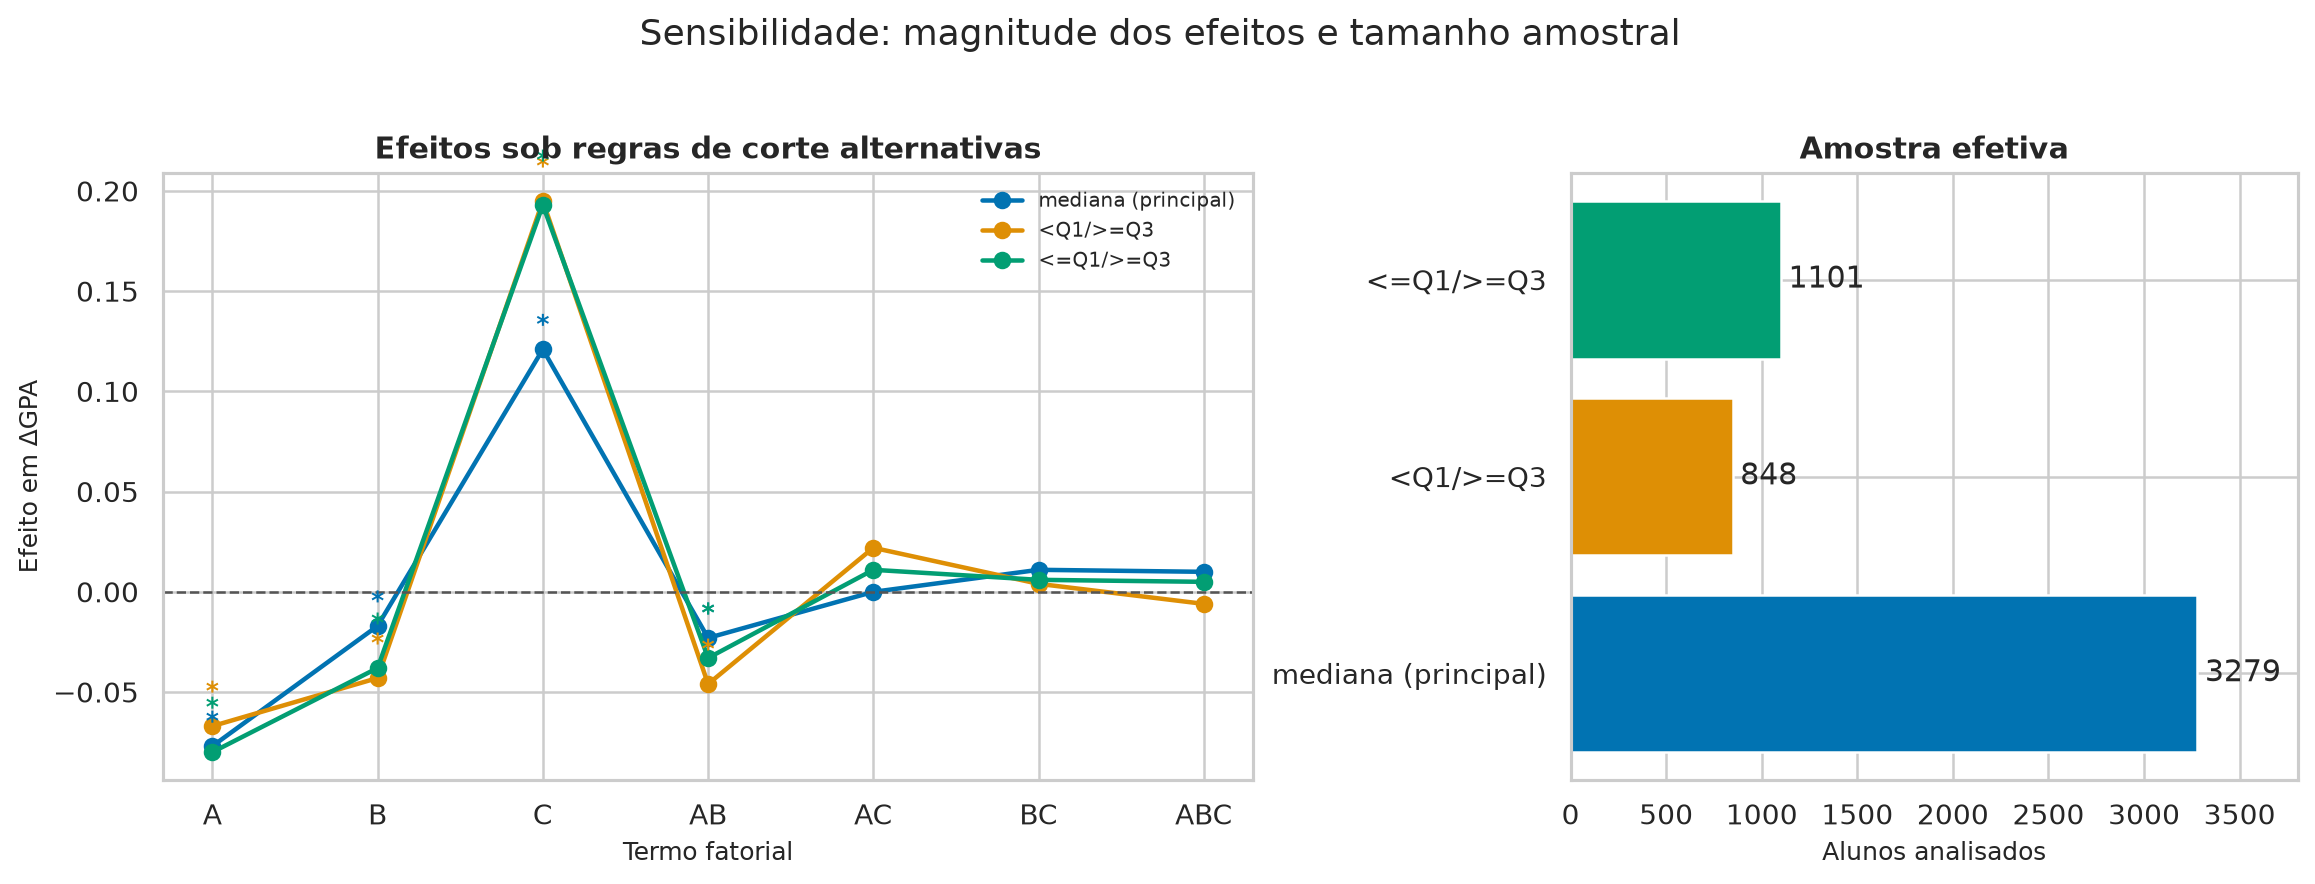

In [3]:
import numpy as np
terms = ["A", "B", "C", "AB", "AC", "BC", "ABC"]
numeric_sensitivity = sensitivity[terms].replace(r"\*", "", regex=True).astype(float)
significant_sensitivity = sensitivity[terms].apply(
    lambda column: column.astype(str).str.contains(r"\*", regex=True)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
for rule_index, (rule, row) in enumerate(numeric_sensitivity.iterrows()):
    line, = axes[0].plot(terms, row[terms], marker="o", linewidth=1.8, label=rule)
    for term_index, term in enumerate(terms):
        if significant_sensitivity.loc[rule, term]:
            axes[0].annotate(
                "*",
                (term, row[term]),
                xytext=(0, 7 + 4 * rule_index),
                textcoords="offset points",
                ha="center",
                color=line.get_color(),
                fontsize=10,
                fontweight="bold",
            )
axes[0].axhline(0, color="#555555", linestyle="--", linewidth=1)
axes[0].set(
    xlabel="Termo fatorial",
    ylabel="Efeito em ΔGPA",
    title="Efeitos sob regras de corte alternativas",
)
axes[0].legend(frameon=False, fontsize=8)
sample_sizes = sensitivity["n"].astype(int)
axes[1].barh(sample_sizes.index, sample_sizes.values, color=sns.color_palette("colorblind", len(sample_sizes)))
axes[1].set(xlabel="Alunos analisados", title="Amostra efetiva")
axes[1].bar_label(axes[1].containers[0], padding=3, fmt="%d")
axes[1].margins(x=0.16)
fig.suptitle("Sensibilidade: magnitude dos efeitos e tamanho amostral", y=1.02)
save_figure(fig, "07_sensibilidade_cortes")


## Diagnósticos que acompanham a conclusão

Separar premissas atendidas de diagnósticos detectados e tratados evita classificar heterocedasticidade como aprovação do modelo.

Figura salva: 07_diagnosticos_resumo.png (PNG) e 07_diagnosticos_resumo.pdf (PDF)


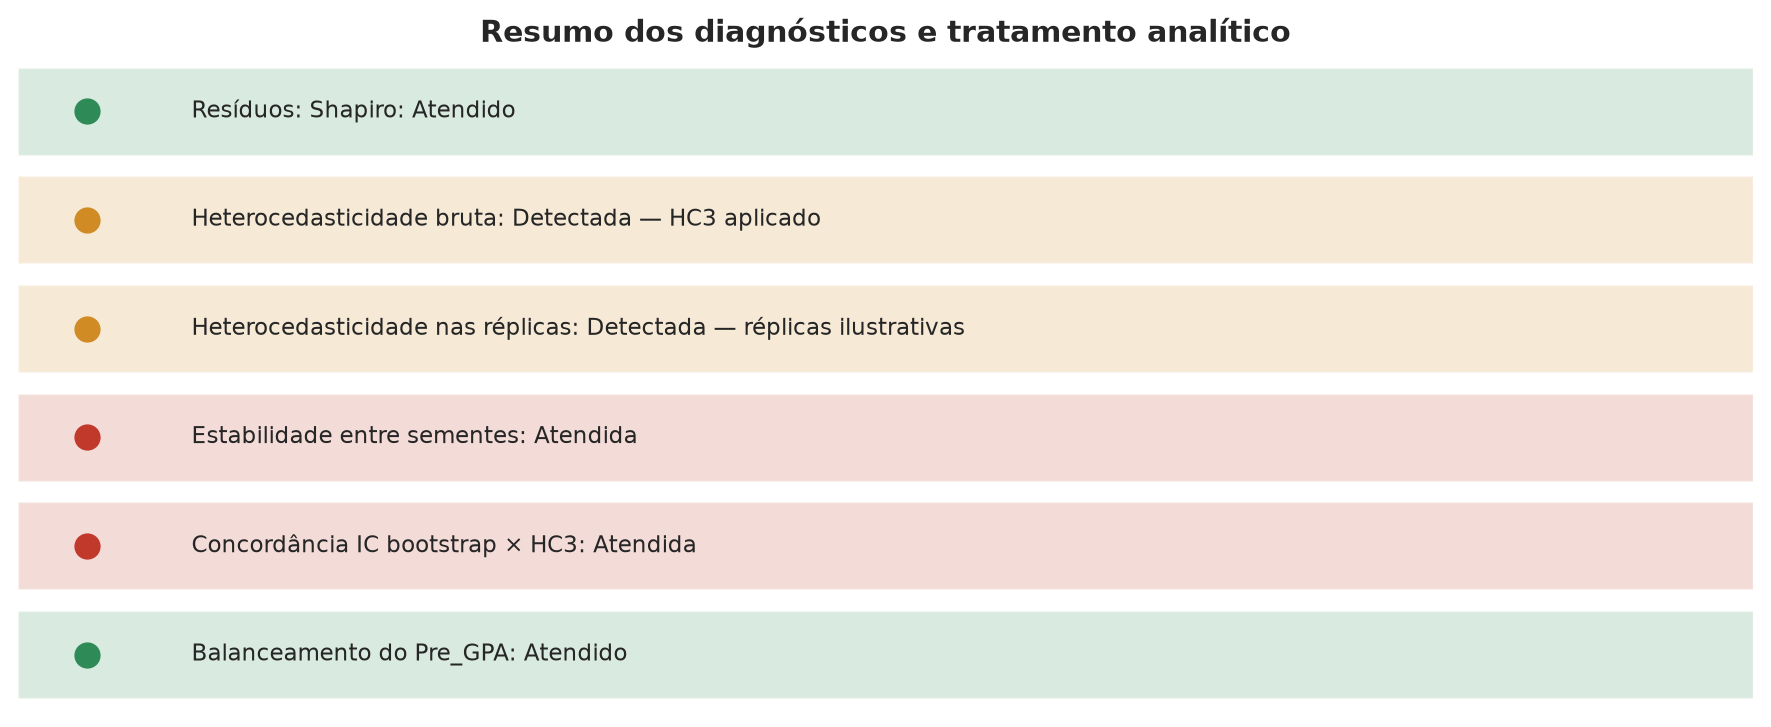

In [4]:
diagnostic_rows = [
    ("Resíduos: Shapiro", "Atendido" if bool(validation.loc[0, "ok"]) else "Revisar"),
    ("Heterocedasticidade bruta", "Detectada — HC3 aplicado"),
    ("Heterocedasticidade nas réplicas", "Detectada — réplicas ilustrativas"),
    ("Estabilidade entre sementes", "Atendida" if bool(validation.loc[3, "ok"]) else "Revisar"),
    ("Concordância IC bootstrap × HC3", "Atendida" if bool(validation.loc[4, "ok"]) else "Revisar"),
    ("Balanceamento do Pre_GPA", "Atendido" if bool(validation.loc[5, "ok"]) else "Revisar"),
]
diagnostic_colors = [
    "#2e8b57" if status == "Atendido" else "#d18b24" if status.startswith("Detectada") else "#c0392b"
    for _, status in diagnostic_rows
]
fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(diagnostic_rows))
ax.barh(positions, np.ones(len(positions)), color=diagnostic_colors, alpha=0.18)
for position, ((label, status), color) in enumerate(zip(diagnostic_rows, diagnostic_colors)):
    ax.scatter(0.04, position, s=90, color=color, zorder=3)
    ax.text(0.1, position, f"{label}: {status}", va="center", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(len(diagnostic_rows) - 0.5, -0.5)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Resumo dos diagnósticos e tratamento analítico")
for spine in ax.spines.values():
    spine.set_visible(False)
save_figure(fig, "07_diagnosticos_resumo")


## Figura de efeitos para o relatório

Figura salva: 07_forest_plot_relatorio.png (PNG) e 07_forest_plot_relatorio.pdf (PDF)


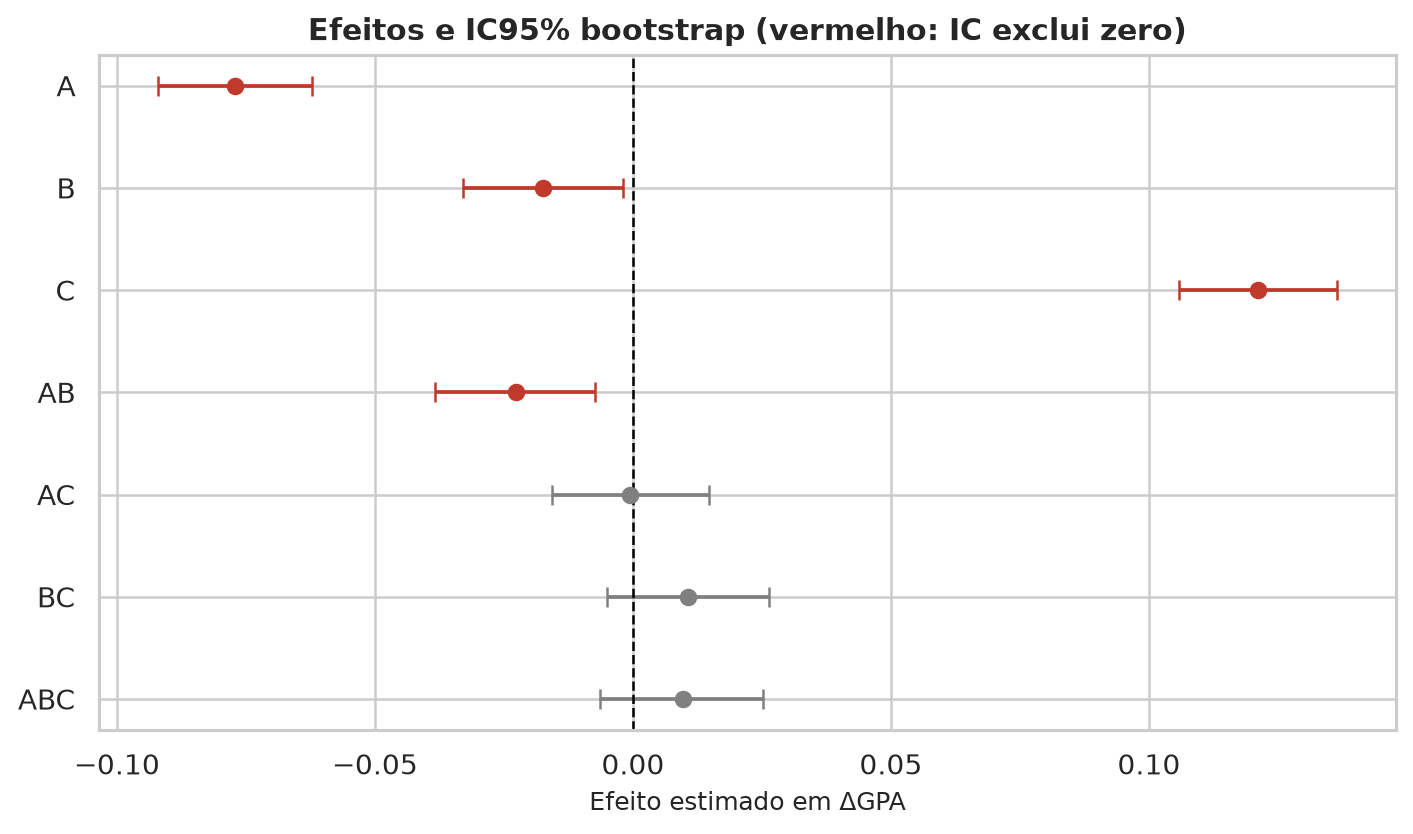

In [5]:

ordered = effects.loc[["ABC", "BC", "AC", "AB", "C", "B", "A"]]
colors = [
    "#c0392b" if (row["ic95_inf"] > 0 or row["ic95_sup"] < 0) else "gray"
    for _, row in ordered.iterrows()
]
fig, ax = plt.subplots(figsize=(8, 4.8))
for position, ((term, row), color) in enumerate(zip(ordered.iterrows(), colors)):
    ax.errorbar(
        row["efeito"], position,
        xerr=[[
            row["efeito"] - row["ic95_inf"],
        ], [
            row["ic95_sup"] - row["efeito"],
        ]],
        fmt="o", color=color, capsize=4,
    )
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(ordered)), ordered.index)
ax.set_xlabel("Efeito estimado em ΔGPA")
ax.set_title("Efeitos e IC95% bootstrap (vermelho: IC exclui zero)")
plt.tight_layout()
save_figure(fig, "07_forest_plot_relatorio")


## Texto-base de resultados
No recorte STEM + Junior, reporte o n, os tamanhos das células, R², efeitos com IC95% bootstrap, p-valores HC3 e os diagnósticos. O código abaixo monta uma síntese numérica a partir dos CSVs atualmente carregados, evitando copiar valores desatualizados.

In [6]:

import statsmodels.formula.api as smf

factorial_results = pd.read_csv(RESULTS / "df_factorial.csv")
model_results = smf.ols("Delta_GPA ~ A * B * C", data=factorial_results).fit()
cell_sizes = factorial_results.groupby("celula").size()
lev_row = validation.loc[
    validation["checagem"].str.startswith("Levene dados brutos"),
    "detalhe",
]
print(
    f"No recorte STEM + Junior, foram analisados {len(factorial_results):,} estudantes "
    f"em oito células (n mínimo={cell_sizes.min()}, máximo={cell_sizes.max()}). "
    f"O modelo fatorial teve R²={model_results.rsquared:.3f}."
)
for term in ["A", "B", "C", "AB", "AC", "BC", "ABC"]:
    row = effects.loc[term]
    print(
        f"{term}: efeito={row['efeito']:+.3f}, "
        f"IC95% [{row['ic95_inf']:+.3f}; {row['ic95_sup']:+.3f}], "
        f"p(HC3)={row['p_hc3']:.4g} ({row['veredito']})."
    )
print(f"Diagnóstico de variâncias: {lev_row.iloc[0]}.")
print(
    "Interpretação: associações observacionais, não efeitos causais. "
    "Considere os ICs bootstrap, HC3 e as análises de sensibilidade em conjunto."
)


No recorte STEM + Junior, foram analisados 3,279 estudantes em oito células (n mínimo=181, máximo=667). O modelo fatorial teve R²=0.129.
A: efeito=-0.077, IC95% [-0.092; -0.062], p(HC3)=0 (significativo).
B: efeito=-0.018, IC95% [-0.033; -0.002], p(HC3)=0.0268 (significativo).
C: efeito=+0.121, IC95% [+0.106; +0.136], p(HC3)=0 (significativo).
AB: efeito=-0.023, IC95% [-0.038; -0.007], p(HC3)=0.0041 (significativo).
AC: efeito=-0.001, IC95% [-0.016; +0.015], p(HC3)=0.9507 (não significativo).
BC: efeito=+0.011, IC95% [-0.005; +0.026], p(HC3)=0.1766 (não significativo).
ABC: efeito=+0.010, IC95% [-0.006; +0.025], p(HC3)=0.2178 (não significativo).
Diagnóstico de variâncias: p=2.6e-05.
Interpretação: associações observacionais, não efeitos causais. Considere os ICs bootstrap, HC3 e as análises de sensibilidade em conjunto.
